# 02.7.1 - Single-Speaker Dlib Method D (96×96 Letterboxed) Video-to-Dataset Pipeline
## Tai Phake Visual Speech Recognition (VSR) Project

---

### Purpose
This notebook provides a dedicated, lightweight, and isolated pipeline to process **a single speaker** from raw `.mp4` video clips all the way to $96 \times 96$ letterboxed Method D cropped frames and conservative lip-reading safe augmentations.

Use this whenever:
1. You have a new, re-recorded, or updated video set for a specific speaker (e.g. `s19`).
2. You want to test, verify, or re-extract cropping landmarks for an individual speaker without re-running all 30 speakers.
3. You want to generate augmented variants (`sX_aug1`, `sX_aug2`, `sX_aug3`) and optionally link them into `data/processed/train` or `data/processed/val`.


## 1. Centralized Single-Speaker Configuration & Paths
Set `TARGET_SPEAKER` below (e.g. `s19`, `s26`, `s35`, etc.). All paths, directories, and augmentations adapt automatically.


In [3]:
# Section 1: Configuration & Environment Setup
import os
import sys
import re
import json
import time
import shutil
import hashlib
import random
from pathlib import Path
from typing import Dict, List, Tuple, Optional, Any

import cv2
import dlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# ==============================================================================
# 1. USER CONFIGURATION: TARGET SPEAKER & SETTINGS
# ==============================================================================
TARGET_SPEAKER = "s48"           # Speaker folder name in VIDEO_INPUT_DIR
SPLIT_ASSIGNMENT = "train"      # "train" or "val" (for metadata & optional symlink)
NUM_AUG_VARIANTS = 3            # Number of augmented folders (e.g., 3 creates sX_aug1, sX_aug2, sX_aug3)
FORCE_REEXTRACT_FRAMES = True   # True = always decode fresh frames from MP4 videos

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_ROOT = PROJECT_ROOT / "data"

# Master Video Source Directory
VIDEO_INPUT_DIR = DATA_ROOT / "experiments" / "digit_videos_only"

# Extraction & Output Directories
EXTRACTED_RAW_FRAMES_DIR = DATA_ROOT / "experiments" / "extracted_raw_frames"
DATASET_NAME = "dlib_augmented_cropped_100_80_20_96x96"
OUTPUT_DATASET_DIR = DATA_ROOT / "experiments" / DATASET_NAME
RESULTS_DIR = PROJECT_ROOT / "results" / "single_speaker_pipeline" / TARGET_SPEAKER
PROCESSED_DIR = DATA_ROOT / "processed"

# Dlib Model File
DLIB_PREDICTOR_PATH = PROJECT_ROOT / "models" / "dlib" / "shape_predictor_68_face_landmarks.dat"

# Method D Letterbox Cropping Parameters
TARGET_WIDTH = 96
TARGET_HEIGHT = 96
PADDING_X = 15      # Horizontal margin in px
PADDING_Y = 10      # Vertical margin in px
BORDER_VALUE = 0    # Black letterbox canvas background
JPEG_QUALITY = 95

# Derived folder names
target_folders = [TARGET_SPEAKER] + [f"{TARGET_SPEAKER}_aug{i}" for i in range(1, NUM_AUG_VARIANTS + 1)]

print("=" * 80)
print(f"SINGLE SPEAKER PIPELINE: {TARGET_SPEAKER}")
print("=" * 80)
print(f"Target Speaker           : {TARGET_SPEAKER}")
print(f"Assigned Split           : {SPLIT_ASSIGNMENT}")
print(f"Folders to Generate ({len(target_folders)}): {target_folders}")
print(f"Video Source Directory   : {VIDEO_INPUT_DIR / TARGET_SPEAKER}")
print(f"Extracted Raw Frames     : {EXTRACTED_RAW_FRAMES_DIR / TARGET_SPEAKER}")
print(f"Output Dataset Root      : {OUTPUT_DATASET_DIR}")
print(f"Results / Diagnostics    : {RESULTS_DIR}")
print(f"Dlib Predictor Model     : {DLIB_PREDICTOR_PATH}")
print(f"Crop Resolution          : {TARGET_WIDTH}x{TARGET_HEIGHT} (Method D Letterbox)")
print(f"Force Re-extract Frames  : {FORCE_REEXTRACT_FRAMES}")
print("=" * 80)


SINGLE SPEAKER PIPELINE: s48
Target Speaker           : s48
Assigned Split           : train
Folders to Generate (4): ['s48', 's48_aug1', 's48_aug2', 's48_aug3']
Video Source Directory   : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/data/experiments/digit_videos_only/s48
Extracted Raw Frames     : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/data/experiments/extracted_raw_frames/s48
Output Dataset Root      : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/data/experiments/dlib_augmented_cropped_100_80_20_96x96
Results / Diagnostics    : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/single_speaker_pipeline/s48
Dlib Predictor Model     : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/models/dlib/shape_predictor_68_face_landmarks.dat
Crop Resolution          : 96x96 (Method D Letterbox)
Force Re-extract Frames  : True


## 2. Video Clip Verification & Sequential Frame Extraction
Scans all 11 digits (`d0` through `d10`) for the target speaker, verifies video streams, and decodes sequential JPEG frames.


In [4]:
# Section 2: Sequential Video Frame Extraction for Target Speaker
def extract_video_frames(
    speaker: str,
    digit: str,
    video_path: Path,
    out_dir: Path,
    save_quality: int = JPEG_QUALITY,
    force_reextract: bool = FORCE_REEXTRACT_FRAMES
) -> Dict[str, Any]:
    out_dir.mkdir(parents=True, exist_ok=True)
    existing_frames = list(out_dir.glob("*.jpg"))

    if not force_reextract and len(existing_frames) > 0:
        return {
            "speaker": speaker,
            "digit": digit,
            "video_path": str(video_path),
            "status": "CACHED",
            "extracted_count": len(existing_frames),
            "error": None
        }

    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        return {
            "speaker": speaker,
            "digit": digit,
            "video_path": str(video_path),
            "status": "FAILED",
            "extracted_count": 0,
            "error": "Failed to open video file"
        }

    frame_count = 0
    while True:
        ret, frame = cap.read()
        if not ret or frame is None:
            break
        frame_count += 1
        out_path = out_dir / f"frame_{frame_count:04d}.jpg"
        cv2.imwrite(str(out_path), frame, [int(cv2.IMWRITE_JPEG_QUALITY), save_quality])
    cap.release()

    return {
        "speaker": speaker,
        "digit": digit,
        "video_path": str(video_path),
        "status": "SUCCESS" if frame_count > 0 else "FAILED",
        "extracted_count": frame_count,
        "error": None if frame_count > 0 else "Zero frames decoded"
    }

spk_video_dir = VIDEO_INPUT_DIR / TARGET_SPEAKER
assert spk_video_dir.exists(), f"Speaker video directory does not exist: {spk_video_dir}"

extraction_tasks = []
for d_idx in range(11):
    dig = f"d{d_idx}"
    dig_dir = spk_video_dir / dig
    assert dig_dir.exists(), f"Missing digit folder: {dig_dir}"
    mp4s = sorted([f for f in dig_dir.iterdir() if f.suffix.lower() == ".mp4" and not f.name.startswith(".")])
    assert len(mp4s) > 0, f"No .mp4 files found in {dig_dir}"
    target_vid = next((v for v in mp4s if v.name == f"{dig}.mp4"), mp4s[0])
    raw_out_dir = EXTRACTED_RAW_FRAMES_DIR / TARGET_SPEAKER / dig
    extraction_tasks.append((TARGET_SPEAKER, dig, target_vid, raw_out_dir))

print(f"Found {len(extraction_tasks)} digit video clips for {TARGET_SPEAKER}.")

extraction_results = []
for spk, dig, vid, out_dir in tqdm(extraction_tasks, desc=f"Extracting {TARGET_SPEAKER}"):
    res = extract_video_frames(spk, dig, vid, out_dir)
    extraction_results.append(res)

df_extract = pd.DataFrame(extraction_results)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
df_extract.to_csv(RESULTS_DIR / "extraction_report.csv", index=False)

print("\n" + "=" * 80)
print(f"FRAME EXTRACTION SUMMARY FOR {TARGET_SPEAKER}")
print("=" * 80)
for _, r in df_extract.iterrows():
    print(f"  {r['digit']:4s}: {r['status']:7s} | {r['extracted_count']:4d} frames | {Path(r['video_path']).name}")
print("-" * 80)
print(f"Total Raw Frames Ready: {df_extract['extracted_count'].sum():,}")
print("=" * 80)


Found 11 digit video clips for s48.


Extracting s48: 100%|██████████| 11/11 [00:11<00:00,  1.02s/it]


FRAME EXTRACTION SUMMARY FOR s48
  d0  : SUCCESS |   13 frames | d0.mp4
  d1  : SUCCESS |   33 frames | d1.mp4
  d2  : SUCCESS |   36 frames | d2.mp4
  d3  : SUCCESS |   38 frames | d3.mp4
  d4  : SUCCESS |   35 frames | d4.mp4
  d5  : SUCCESS |   37 frames | d5.mp4
  d6  : SUCCESS |   46 frames | d6.mp4
  d7  : SUCCESS |   38 frames | d7.mp4
  d8  : SUCCESS |   34 frames | d8.mp4
  d9  : SUCCESS |   47 frames | d9.mp4
  d10 : SUCCESS |  339 frames | d10.mp4
--------------------------------------------------------------------------------
Total Raw Frames Ready: 696


## 3. Dlib Method D Cropping & Conservative Augmentations
- **Mouth Contours**: Points 48–67 tracked across frames with temporal fallback (`last_rect`, `last_geom`).
- **Method D**: Proportional aspect scaling and centered letterboxing onto a neutral black $96 \times 96$ canvas.
- **Lip-Reading Safe Augmentation**: Utterance-consistent affine matrix $M$ (max $\pm 3$ px translation, $\pm 3^\circ$ rotation, $0.97\text{--}1.03$ scale) with `cv2.BORDER_REFLECT_101` and per-frame photometric variations.


In [5]:
# Section 3: Cropping & Augmentation Functions
assert DLIB_PREDICTOR_PATH.exists(), f"Dlib predictor file not found at: {DLIB_PREDICTOR_PATH}"

detector = dlib.get_frontal_face_detector()
predictor = dlib.shape_predictor(str(DLIB_PREDICTOR_PATH))

def extract_method_d_crop(
    img: np.ndarray,
    center_x: float,
    center_y: float,
    raw_width: float,
    raw_height: float,
    pad_x: int = PADDING_X,
    pad_y: int = PADDING_Y,
    canvas_size: int = TARGET_WIDTH,
    border_val: int = BORDER_VALUE
) -> Tuple[np.ndarray, int, int, int, int]:
    h_img, w_img = img.shape[:2]
    min_x = center_x - raw_width / 2.0
    max_x = center_x + raw_width / 2.0
    min_y = center_y - raw_height / 2.0
    max_y = center_y + raw_height / 2.0

    x1 = max(0, int(round(min_x - pad_x)))
    y1 = max(0, int(round(min_y - pad_y)))
    x2 = min(w_img, int(round(max_x + pad_x)))
    y2 = min(h_img, int(round(max_y + pad_y)))

    roi = img[y1:y2, x1:x2]
    h_roi, w_roi = roi.shape[:2]
    if h_roi == 0 or w_roi == 0:
        return np.full((canvas_size, canvas_size, 3), border_val, dtype=np.uint8), 0, 0, 0, 0

    scale = canvas_size / max(w_roi, h_roi)
    new_w = min(canvas_size, max(1, int(round(w_roi * scale))))
    new_h = min(canvas_size, max(1, int(round(h_roi * scale))))
    resized_roi = cv2.resize(roi, (new_w, new_h), interpolation=cv2.INTER_AREA)

    canvas = np.full((canvas_size, canvas_size, 3), border_val, dtype=np.uint8)
    offset_x = (canvas_size - new_w) // 2
    offset_y = (canvas_size - new_h) // 2
    canvas[offset_y:offset_y + new_h, offset_x:offset_x + new_w] = resized_roi
    return canvas, new_w, new_h, canvas_size - new_w, canvas_size - new_h

def get_geometric_rng(base_seed: int, speaker: str, digit: str, variant_idx: int) -> np.random.Generator:
    key = f"{base_seed}_{speaker}_{digit}_aug{variant_idx}_geom".encode("utf-8")
    return np.random.default_rng(int.from_bytes(hashlib.sha256(key).digest()[:4], byteorder="little"))

def get_photometric_rng(base_seed: int, speaker: str, digit: str, frame: str, variant_idx: int) -> np.random.Generator:
    key = f"{base_seed}_{speaker}_{digit}_{frame}_aug{variant_idx}_photo".encode("utf-8")
    return np.random.default_rng(int.from_bytes(hashlib.sha256(key).digest()[:4], byteorder="little"))

def sample_geometric_transform(rng: np.random.Generator, width: int = TARGET_WIDTH, height: int = TARGET_HEIGHT) -> np.ndarray:
    tx = float(rng.uniform(-3.0, 3.0))
    ty = float(rng.uniform(-3.0, 3.0))
    angle = float(rng.uniform(-3.0, 3.0))
    scale = float(rng.uniform(0.97, 1.03))
    M = cv2.getRotationMatrix2D((width / 2.0, height / 2.0), angle, scale)
    M[0, 2] += tx
    M[1, 2] += ty
    return M

def apply_conservative_augmentation(img: np.ndarray, M: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    h, w = img.shape[:2]
    # 1. Geometric warp with reflection border
    transformed = cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
    # 2. Photometric: Contrast (0.92 - 1.08) and Brightness (-10 to +10)
    alpha = float(rng.uniform(0.92, 1.08))
    beta = float(rng.uniform(-10.0, 10.0))
    photo = np.clip(alpha * transformed.astype(np.float32) + beta, 0.0, 255.0).astype(np.uint8)
    # 3. Gaussian sensor noise (50% prob)
    if rng.random() < 0.50:
        sigma = float(rng.uniform(1.0, 3.5))
        photo = np.clip(photo.astype(np.float32) + rng.normal(0.0, sigma, photo.shape), 0.0, 255.0).astype(np.uint8)
    # 4. Mild Gaussian blur (30% prob)
    if rng.random() < 0.30:
        photo = cv2.GaussianBlur(photo, (3, 3), 0.5)
    return photo

print("Dlib models loaded and augmentation functions initialized.")


Dlib models loaded and augmentation functions initialized.


## 4. Execute Method D Letterbox Cropping & Augmentation for Target Speaker
Generates the base cropped folder (`TARGET_SPEAKER`) and all requested augmented folders (`TARGET_SPEAKER_aug1`, `TARGET_SPEAKER_aug2`, …).


In [6]:
# Section 4: Execution
raw_spk_dir = EXTRACTED_RAW_FRAMES_DIR / TARGET_SPEAKER
assert raw_spk_dir.exists(), f"Raw frames directory not found: {raw_spk_dir}"

def natural_sort_key(s: str) -> int:
    m = re.search(r"\d+", s)
    return int(m.group(0)) if m else 0

digit_dirs = sorted([d for d in raw_spk_dir.iterdir() if d.is_dir() and not d.name.startswith(".")], key=lambda x: natural_sort_key(x.name))
aug_variants = [f for f in target_folders if f != TARGET_SPEAKER]

# Sample sequence-consistent geometric transforms once per (digit, variant)
geo_transforms = {}
for dig_dir in digit_dirs:
    dig = dig_dir.name
    for v_folder in aug_variants:
        m = re.search(r"aug(\d+)", v_folder)
        v_idx = int(m.group(1)) if m else 1
        geo_rng = get_geometric_rng(SEED, TARGET_SPEAKER, dig, v_idx)
        geo_transforms[(dig, v_folder)] = sample_geometric_transform(geo_rng, TARGET_WIDTH, TARGET_HEIGHT)

manifest_records = []
geom_records = []

for dig_dir in tqdm(digit_dirs, desc=f"Cropping {TARGET_SPEAKER}"):
    dig = dig_dir.name
    frames = sorted([f for f in dig_dir.glob("*.jpg") if not f.name.startswith(".")], key=lambda x: natural_sort_key(x.name))
    if not frames:
        continue

    last_rect = None
    last_geom = None

    for fpath in frames:
        fname = fpath.name
        raw_img = cv2.imread(str(fpath))
        if raw_img is None:
            continue

        # 1. Landmark detection with temporal fallback
        gray = cv2.cvtColor(raw_img, cv2.COLOR_BGR2GRAY)
        faces = detector(gray, 0)
        rect = faces[0] if faces else last_rect
        if faces:
            last_rect = rect

        geom = None
        if rect is not None:
            try:
                shape = predictor(gray, rect)
                pts = np.array([[shape.part(i).x, shape.part(i).y] for i in range(48, 68)], dtype=np.float32)
                min_x, min_y = pts.min(axis=0)
                max_x, max_y = pts.max(axis=0)
                geom = {
                    "center_x": float((min_x + max_x) / 2.0),
                    "center_y": float((min_y + max_y) / 2.0),
                    "raw_width": float(max_x - min_x),
                    "raw_height": float(max_y - min_y)
                }
                last_geom = geom
            except Exception:
                geom = last_geom
        else:
            geom = last_geom

        # 2. Extract Method D 96x96 letterbox crop
        if geom is not None:
            crop_img, sw, sh, ph, pv = extract_method_d_crop(
                raw_img, geom["center_x"], geom["center_y"], geom["raw_width"], geom["raw_height"],
                PADDING_X, PADDING_Y, TARGET_WIDTH, BORDER_VALUE
            )
        else:
            h_i, w_i = raw_img.shape[:2]
            crop_img, sw, sh, ph, pv = extract_method_d_crop(
                raw_img, w_i / 2.0, h_i / 2.0, 100.0, 50.0,
                PADDING_X, PADDING_Y, TARGET_WIDTH, BORDER_VALUE
            )

        # 3. Save original Method D crop
        orig_dir = OUTPUT_DATASET_DIR / TARGET_SPEAKER / dig
        orig_dir.mkdir(parents=True, exist_ok=True)
        orig_file = orig_dir / fname
        cv2.imwrite(str(orig_file), crop_img, [int(cv2.IMWRITE_JPEG_QUALITY), JPEG_QUALITY])

        manifest_records.append({
            "split": SPLIT_ASSIGNMENT,
            "base_speaker": TARGET_SPEAKER,
            "folder_name": TARGET_SPEAKER,
            "is_augmented": False,
            "variant": "original",
            "digit": dig,
            "frame": fname,
            "output_path": str(orig_file)
        })

        geom_records.append({
            "speaker": TARGET_SPEAKER,
            "digit": dig,
            "frame": fname,
            "status": "SUCCESS" if geom is not None else "FALLBACK",
            "scaled_w": sw,
            "scaled_h": sh
        })

        # 4. Generate and save augmented variants
        for v_folder in aug_variants:
            m = re.search(r"aug(\d+)", v_folder)
            v_idx = int(m.group(1)) if m else 1
            M = geo_transforms.get((dig, v_folder))
            photo_rng = get_photometric_rng(SEED, TARGET_SPEAKER, dig, fname, v_idx)
            aug_img = apply_conservative_augmentation(crop_img, M, photo_rng)

            aug_dir = OUTPUT_DATASET_DIR / v_folder / dig
            aug_dir.mkdir(parents=True, exist_ok=True)
            aug_file = aug_dir / fname
            cv2.imwrite(str(aug_file), aug_img, [int(cv2.IMWRITE_JPEG_QUALITY), JPEG_QUALITY])

            manifest_records.append({
                "split": SPLIT_ASSIGNMENT,
                "base_speaker": TARGET_SPEAKER,
                "folder_name": v_folder,
                "is_augmented": True,
                "variant": f"aug{v_idx}",
                "digit": dig,
                "frame": fname,
                "output_path": str(aug_file)
            })

df_spk_manifest = pd.DataFrame(manifest_records)
df_spk_geom = pd.DataFrame(geom_records)

df_spk_manifest.to_csv(RESULTS_DIR / "manifest.csv", index=False)
df_spk_geom.to_csv(RESULTS_DIR / "cropping_geometry.csv", index=False)

print("\n" + "=" * 80)
print(f"CROPPING & AUGMENTATION SUMMARY FOR {TARGET_SPEAKER}")
print("=" * 80)
print(f"Total Generated Frames : {len(df_spk_manifest):,}")
print(f"Original Crops         : {len(df_spk_manifest[~df_spk_manifest['is_augmented']]):,}")
print(f"Augmented Crops        : {len(df_spk_manifest[df_spk_manifest['is_augmented']]):,}")
print(f"Generated Folders      : {sorted(df_spk_manifest['folder_name'].unique())}")
success_rate = (df_spk_geom['status'] == 'SUCCESS').mean() * 100
print(f"Landmark Success Rate  : {success_rate:.2f}%")
print(f"Saved manifest to      : {RESULTS_DIR / 'manifest.csv'}")
print("=" * 80)


Cropping s48: 100%|██████████| 11/11 [03:55<00:00, 21.42s/it]


CROPPING & AUGMENTATION SUMMARY FOR s48
Total Generated Frames : 2,784
Original Crops         : 696
Augmented Crops        : 2,088
Generated Folders      : ['s48', 's48_aug1', 's48_aug2', 's48_aug3']
Landmark Success Rate  : 100.00%
Saved manifest to      : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/single_speaker_pipeline/s48/manifest.csv


## 5. Optional Symlinking to `data/processed/`
If you want to immediately mount the generated folders (`sX`, `sX_aug1`, …) into `data/processed/train` or `data/processed/val`, run this cell.


In [7]:
# Section 5: Optional Symlink Mounting
target_mount_dir = PROCESSED_DIR / SPLIT_ASSIGNMENT
target_mount_dir.mkdir(parents=True, exist_ok=True)

mounted_links = []
for folder in target_folders:
    src_folder = OUTPUT_DATASET_DIR / folder
    dst_link = target_mount_dir / folder
    if dst_link.is_symlink() or dst_link.exists():
        dst_link.unlink()
    dst_link.symlink_to(src_folder.resolve())
    mounted_links.append(dst_link)

print(f"Mounted {len(mounted_links)} folders into {target_mount_dir}:")
for l in mounted_links:
    print(f"  {l.name} -> {l.resolve()}")


Mounted 4 folders into /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/data/processed/train:
  s48 -> /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/data/experiments/dlib_augmented_cropped_100_80_20_96x96/s48
  s48_aug1 -> /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/data/experiments/dlib_augmented_cropped_100_80_20_96x96/s48_aug1
  s48_aug2 -> /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/data/experiments/dlib_augmented_cropped_100_80_20_96x96/s48_aug2
  s48_aug3 -> /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/data/experiments/dlib_augmented_cropped_100_80_20_96x96/s48_aug3


## 6. Visual Preview & Inspection Grid
Renders a sample of the cropped Method D letterboxed frames across all digits for the original speaker and an augmented variant.


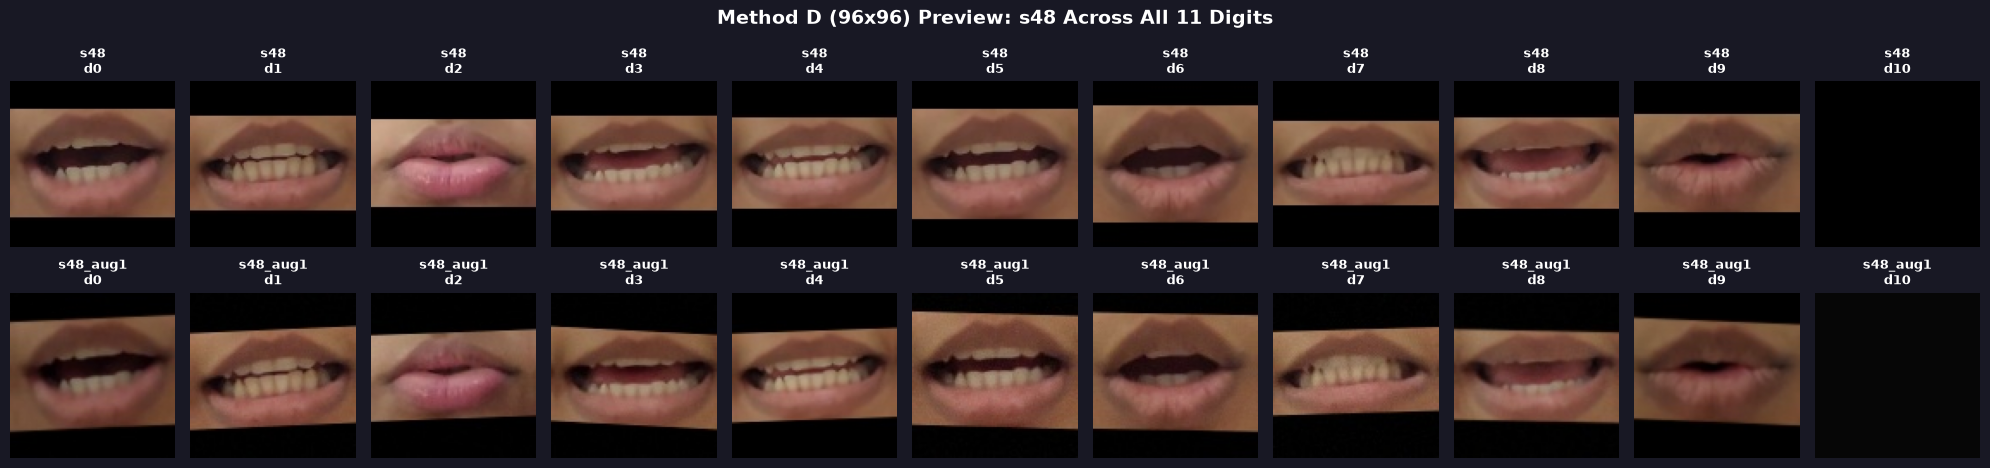

Preview saved to: /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/single_speaker_pipeline/s48/s48_preview_grid.png


In [8]:
# Section 6: Visual Preview Grid
preview_folders = [TARGET_SPEAKER]
if NUM_AUG_VARIANTS > 0:
    preview_folders.append(f"{TARGET_SPEAKER}_aug1")

preview_digits = [f"d{i}" for i in range(11)]

fig, axes = plt.subplots(len(preview_folders), len(preview_digits), figsize=(20, 2 * len(preview_folders) + 1))
fig.patch.set_facecolor("#181824")

if len(preview_folders) == 1:
    axes = np.expand_dims(axes, 0)

for r_idx, folder in enumerate(preview_folders):
    for c_idx, dig in enumerate(preview_digits):
        ax = axes[r_idx, c_idx]
        ax.set_facecolor("#12121c")
        dig_dir = OUTPUT_DATASET_DIR / folder / dig
        frames = sorted(list(dig_dir.glob("*.jpg"))) if dig_dir.exists() else []
        if frames:
            mid_frame = frames[len(frames) // 2]
            img = cv2.imread(str(mid_frame))
            if img is not None:
                img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                ax.imshow(img_rgb)
                ax.set_title(f"{folder}\n{dig}", color="white", fontsize=9, fontweight="bold")
        ax.axis("off")

plt.suptitle(f"Method D (96x96) Preview: {TARGET_SPEAKER} Across All 11 Digits", color="white", fontsize=14, fontweight="bold", y=0.98)
plt.tight_layout()
preview_path = RESULTS_DIR / f"{TARGET_SPEAKER}_preview_grid.png"
plt.savefig(preview_path, dpi=150, facecolor=fig.get_facecolor(), bbox_inches="tight")
plt.show()
print(f"Preview saved to: {preview_path}")
